# AI Workforce Investment Intelligence — data download & preprocessing
**CS3216 Time Series Analysis and Forecasting · team project**

This notebook downloads the project datasets, cleans them, and builds modelling-ready time series.
It also runs the first **Module 1 / Module 3 readiness checks** (decomposition, ADF/KPSS, ACF/PACF) so the review can see the data is fit for forecasting.

| # | Dataset | Feeds |
|---|---|---|
| 1 | BurstGPT (Azure OpenAI request trace) | Token expenditure: hourly/daily tokens by model and API vs chat, request rate, peaks |
| 2 | WildChat (Allen AI chat logs) | Token expenditure trend; workforce-enablement proxies (new/returning users) |
| 3 | BLS Employment Cost Index (FRED) | Cost of people's time (enablement, integration, value of time saved) |
| 4 | FRED PPI — data processing & hosting | Cloud price trend |
| 5 | Epoch AI LLM prices (manual upload) | Price per token → turns tokens into money |
| 6 | FRED Generative AI Adoption Tracker | Business outcomes: share of work hours saved |
| 7 | METR developer RCT | Downside case for time saved |

**How to run:** `Runtime → Run all`. Re-running is safe — finished downloads are skipped.
Sections whose raw data is missing are skipped with a message.


## 0. Settings

In [1]:
# ---- Edit these -------------------------------------------------------
USE_DRIVE = True              # save data to Google Drive so it survives runtime resets (recommended)
WILDCHAT_REPO = "allenai/WildChat-4.8M"   # or "allenai/WildChat-1M" (smaller, Apr 2023 - May 2024)
WILDCHAT_SHARDS = 5           # start small; set to None for all shards (~12 GB, run overnight)
DOWNLOAD = True               # set False to only re-run preprocessing on files already downloaded
# ------------------------------------------------------------------------

import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/ai-workforce-intel"
elif IN_COLAB:
    BASE = "/content/ai-workforce-intel"
else:
    BASE = os.environ.get("AWI_BASE", os.path.abspath("ai-workforce-intel"))
print("Project folder:", BASE)

Project folder: c:\Users\Isha Jain\Downloads\ai-workforce-intel


In [2]:
# Colab already has pandas, numpy, statsmodels, matplotlib and pyarrow.
%pip install -q -U huggingface_hub

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.0.1 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
gradio 6.24.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.4.0 which is incompatible.
gradio-client 2.6.0 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.4.0 which is incompatible.
tokenizers 0.22.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.4.0 which is incompatible.
transformers 5.15.0 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.4.0 which is incompatible.


## 1. Shared helpers
Paths, a `save()` that writes Parquet (for code) and CSV (to inspect), a quality log, and an ADF + KPSS summary used for every series.

In [3]:
from pathlib import Path
import json

import pandas as pd

ROOT = Path(BASE)

RAW = ROOT / "data" / "raw"

PROCESSED = ROOT / "data" / "processed"

REPORTS = ROOT / "reports"

FIGURES = REPORTS / "figures"

for p in (RAW, PROCESSED, REPORTS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)

# One log entry per dataset, collected into reports/data_quality.md at the end.
_QUALITY: dict[str, dict] = {}

def save(df: pd.DataFrame, name: str) -> Path:
    """Save a processed table as Parquet (for code) and CSV (for quick inspection)."""
    pq = PROCESSED / f"{name}.parquet"
    df.to_parquet(pq, index=False)
    df.to_csv(PROCESSED / f"{name}.csv", index=False)
    print(f"  saved {name}: {len(df):,} rows x {df.shape[1]} cols")
    return pq

def log_quality(dataset: str, **facts) -> None:
    _QUALITY.setdefault(dataset, {}).update(facts)

def write_quality_report() -> Path:
    lines = ["# Data quality report", "",
             "Generated by `python src/run_all.py`. Re-run after adding new raw files.", ""]
    for ds, facts in _QUALITY.items():
        lines.append(f"## {ds}")
        lines.append("")
        for k, v in facts.items():
            if isinstance(v, (dict, list)):
                v = "`" + json.dumps(v, default=str) + "`"
            lines.append(f"- **{k}:** {v}")
        lines.append("")
    out = REPORTS / "data_quality.md"
    out.write_text("\n".join(lines), encoding="utf-8")
    print(f"Quality report -> {out}")
    return out

def adf_summary(series: pd.Series) -> dict:
    """ADF + KPSS snapshot so the review can show stationarity status per series."""
    from statsmodels.tsa.stattools import adfuller, kpss
    import warnings

    s = series.dropna().astype(float)
    if len(s) < 12:
        return {"n": len(s), "note": "too short for tests"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf_p = adfuller(s, autolag="AIC")[1]
        kpss_p = kpss(s, regression="c", nlags="auto")[1]
    verdict = "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "non-stationary (difference before ARMA)"
    return {"n": len(s), "adf_p": round(adf_p, 4), "kpss_p": round(kpss_p, 4), "verdict": verdict}

## 2. Download
BurstGPT and METR come from GitHub, FRED series as CSV without an API key, WildChat from Hugging Face. Epoch AI is a manual upload (next cell group).

In [4]:
from pathlib import Path
import requests

HEADERS = {"User-Agent": "TSAF student project (data download)"}

BURSTGPT_FILES = {
    # In the repo itself (verified): first 2 months, includes failures.
    "BurstGPT_1.csv": "https://raw.githubusercontent.com/HPMLL/BurstGPT/main/data/BurstGPT_1.csv",
    # Release assets (months 3-4). If this 404s, download from
    # https://github.com/HPMLL/BurstGPT/releases manually into data/raw/burstgpt/.
    "BurstGPT_2.csv": "https://github.com/HPMLL/BurstGPT/releases/download/v1.1/BurstGPT_2.csv",
}

METR_FILES = {
    "data_complete.csv": "https://raw.githubusercontent.com/METR/Measuring-Early-2025-AI-on-Exp-OSS-Devs/main/data_complete.csv",
}

# FRED series, downloaded as CSV without an API key.
FRED_SERIES = {
    # Labour cost (quarterly)
    "CIS202540A000000I": "ECI wages, professional & business services, SA",
    "CIU202540A000000I": "ECI wages, professional & business services, NSA",
    # Cloud / hosting prices (monthly)
    "PCU518210518210": "PPI data processing, hosting & related services",
    "PCU5182105182105": "PPI hosting, ASP & IT infrastructure provisioning",
    # Generative AI Adoption Tracker (quarterly) - national
    "RPSGENAITSALL": "GenAI time savings, % of work hours, all employed adults",
    "RPSGENAIASSISTWRKHRSALL": "GenAI work hours assisted, %, all employed adults",
    # Tracker - occupation / industry time-savings panels (pooled outcome model)
    "RPSGENAITSOCC2": "GenAI time savings: business & financial operations occ.",
    "RPSGENAITSOCC4": "GenAI time savings: architecture & engineering occ.",
    "RPSGENAITSOCC6": "GenAI time savings: community & social service occ.",
    "RPSGENAITSOCC11": "GenAI time savings: healthcare support occ.",
    "RPSGENAITSIND5": "GenAI time savings: wholesale trade",
    "RPSGENAITSIND7": "GenAI time savings: transportation & warehousing",
    "RPSGENAITSIND14": "GenAI time savings: admin & support services",
    "RPSGENAITSIND19": "GenAI time savings: other services",
}

def fetch(url: str, dest: Path, chunk: int = 1 << 20) -> bool:
    if dest.exists() and dest.stat().st_size > 0:
        print(f"  skip (exists) {dest.name}")
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    try:
        with requests.get(url, headers=HEADERS, stream=True, timeout=120) as r:
            r.raise_for_status()
            tmp = dest.with_suffix(dest.suffix + ".part")
            with open(tmp, "wb") as f:
                for block in r.iter_content(chunk):
                    f.write(block)
            tmp.rename(dest)
        print(f"  ok   {dest.name} ({dest.stat().st_size / 1e6:.1f} MB)")
        return True
    except Exception as e:  # report and continue with the rest
        print(f"  FAIL {dest.name}: {e}")
        return False

def get_burstgpt():
    print("BurstGPT")
    for name, url in BURSTGPT_FILES.items():
        fetch(url, RAW / "burstgpt" / name)

def get_metr():
    print("METR RCT")
    for name, url in METR_FILES.items():
        fetch(url, RAW / "metr" / name)

def get_fred():
    print("FRED / BLS series")
    for sid in FRED_SERIES:
        fetch(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}", RAW / "fred" / f"{sid}.csv")

def get_wildchat(repo: str, shards: int | None):
    """Download WildChat Parquet shards from Hugging Face.

    The full 4.8M set is ~12 GB. `shards` limits how many files are fetched;
    shards are roughly chronological, so take enough to cover the period you
    need, or all of them for the final run.
    """
    print(f"WildChat ({repo})")
    from huggingface_hub import HfApi, hf_hub_download

    files = sorted(f for f in HfApi().list_repo_files(repo, repo_type="dataset")
                   if f.startswith("data/") and f.endswith(".parquet"))
    if shards:
        files = files[:shards]
    print(f"  {len(files)} shard(s) to fetch")
    out = RAW / "wildchat"
    for f in files:
        if (out / f).exists():
            print(f"  skip (exists) {f}")
            continue
        hf_hub_download(repo, f, repo_type="dataset", local_dir=out)
        print(f"  ok   {f}")

In [5]:
if DOWNLOAD:
    get_burstgpt()
    get_metr()
    get_fred()
    try:
        get_wildchat(WILDCHAT_REPO, WILDCHAT_SHARDS)
    except Exception as e:
        print("WildChat download failed:", e)
        print("If it asks for a login: run `from huggingface_hub import notebook_login; notebook_login()` "
              "and accept the dataset terms on its Hugging Face page.")

BurstGPT
  ok   BurstGPT_1.csv (50.9 MB)
  ok   BurstGPT_2.csv (144.8 MB)
METR RCT
  ok   data_complete.csv (0.0 MB)
FRED / BLS series
  FAIL CIS202540A000000I.csv: HTTPSConnectionPool(host='fred.stlouisfed.org', port=443): Read timed out. (read timeout=120)
  FAIL CIU202540A000000I.csv: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
  FAIL PCU518210518210.csv: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
  FAIL PCU5182105182105.csv: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
  FAIL RPSGENAITSALL.csv: HTTPSConnectionPool(host='fred.stlouisfed.org', port=443): Read timed out. (read timeout=120)
  FAIL RPSGENAIASSISTWRKHRSALL.csv: HTTPSConnectionPool(host='fred.stlouisfed.org', port=443): Read timed out. (read timeou

data/train-00000-of-00086.parquet: reconstructing file:   0%|          |  0.00B /  126MB            

data/train-00000-of-00086.parquet: downloading bytes:           |  0.00B            

  ok   data/train-00000-of-00086.parquet


data/train-00001-of-00086.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

data/train-00001-of-00086.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

  ok   data/train-00003-of-00086.parquet


data/train-00004-of-00086.parquet: reconstructing file:   0%|          |  0.00B /  127MB            

data/train-00004-of-00086.parquet: downloading bytes:           |  0.00B            

  ok   data/train-00004-of-00086.parquet


### Epoch AI price data (manual)
1. Open Epoch AI's data hub (epoch.ai → *Data*) and download the LLM pricing / benchmarking CSV.
2. Run the cell below and upload it. It is saved in `data/raw/epoch/`.

Skip this if you don't have the file yet — the Epoch section will be skipped.

In [6]:
(RAW / "epoch").mkdir(parents=True, exist_ok=True)
if IN_COLAB and not list((RAW / "epoch").glob("*.csv")):
    from google.colab import files
    up = files.upload()
    for name, data in up.items():
        (RAW / "epoch" / name).write_bytes(data)
print("Epoch files:", [p.name for p in (RAW / "epoch").glob("*.csv")])

Epoch files: []


In [7]:
# What has been downloaded?
for p in sorted(RAW.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(RAW)!s:60s} {p.stat().st_size/1e6:8.1f} MB")

burstgpt\BurstGPT_1.csv                                          50.9 MB
burstgpt\BurstGPT_2.csv                                         144.8 MB
metr\data_complete.csv                                            0.0 MB
wildchat\.cache\huggingface\.gitignore                            0.0 MB
wildchat\.cache\huggingface\CACHEDIR.TAG                          0.0 MB
wildchat\.cache\huggingface\download\data\train-00000-of-00086.parquet.metadata      0.0 MB
wildchat\.cache\huggingface\download\data\train-00001-of-00086.parquet.metadata      0.0 MB
wildchat\.cache\huggingface\download\data\train-00002-of-00086.parquet.metadata      0.0 MB
wildchat\.cache\huggingface\download\data\train-00003-of-00086.parquet.metadata      0.0 MB
wildchat\.cache\huggingface\download\data\train-00004-of-00086.parquet.metadata      0.0 MB
wildchat\data\train-00000-of-00086.parquet                      125.5 MB
wildchat\data\train-00001-of-00086.parquet                      120.5 MB
wildchat\data\train-00002-of-

## 3. BurstGPT — AI consumption (core dataset)

**Preprocessing decisions**
- `Timestamp` = **seconds since the trace started**, not a date → indexed as hour/day since start; `day_of_cycle` (0–6) is the weekly position. The weekend is *inferred* from the weekly pattern, not assumed.
- Exact duplicate rows are **kept**: identical requests in the same second are real batched API traffic.
- Failed requests (0 response tokens) are kept and flagged; failure rate is its own series.
- Quiet hours/days are filled with 0 (complete time grid); the last, partial day is flagged.
- **Copied days are detected and removed.** Each day gets an order-independent fingerprint; in the published trace, **days 87–91 are exact copies of days 81–85** (~483,000 rows). Their values become *missing*, not zero.
- **Low-activity regime flagged:** 3+ consecutive days below 10% of median requests (days 93–110: API traffic stops). Single low days (day 77, likely an outage) are flagged as anomalies but kept.
- **Modelling window** = longest run of clean, normal days (`in_model_window`, days 0–86). Models train and backtest inside it.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd

COLS = {"Timestamp": "t_sec", "Model": "model", "Request tokens": "request_tokens",
        "Response tokens": "response_tokens", "Total tokens": "total_tokens", "Log Type": "log_type"}

In [9]:
def load() -> pd.DataFrame:
    files = sorted((RAW / "burstgpt").glob("BurstGPT_[0-9].csv"))
    if not files:
        raise FileNotFoundError("No BurstGPT_*.csv in data/raw/burstgpt - run download.py first")
    parts, offset = [], 0
    for f in files:
        d = pd.read_csv(f).rename(columns=COLS)
        # If a later file restarts its clock, shift it to follow the previous one.
        if parts and d["t_sec"].min() < offset:
            d["t_sec"] += offset
            log_quality("BurstGPT", **{f"{f.name} clock": f"restarted; shifted by {offset} s"})
        offset = int(d["t_sec"].max()) + 1
        d["source_file"] = f.name
        parts.append(d)
    return pd.concat(parts, ignore_index=True)

In [10]:
def clean(d: pd.DataFrame) -> pd.DataFrame:
    n0 = len(d)
    d = d.dropna(subset=["t_sec", "model", "log_type"])
    d = d[(d["request_tokens"] >= 0) & (d["response_tokens"] >= 0)]
    d["log_type"] = d["log_type"].str.replace(" log", "", regex=False).str.lower()  # api / conversation
    d["model"] = d["model"].str.strip()
    d["failed"] = (d["response_tokens"] == 0).astype("int8")
    # Total tokens should equal request + response; keep the recomputed value.
    mismatch = int((d["total_tokens"] != d["request_tokens"] + d["response_tokens"]).sum())
    d["total_tokens"] = d["request_tokens"] + d["response_tokens"]
    # Exact duplicate rows are NOT removed: in a request log, identical requests in the
    # same second are real traffic (e.g. batched API calls). We only report the count.
    dup_rows = int(d.duplicated().sum())
    d = d.sort_values("t_sec", kind="stable")
    d["minute_index"] = (d["t_sec"] // 60).astype("int64")
    d["hour_index"] = (d["t_sec"] // 3600).astype("int64")
    d["day_index"] = (d["t_sec"] // 86400).astype("int64")
    for c in ("model", "log_type"):
        d[c] = d[c].astype("category")
    log_quality("BurstGPT",
                files=sorted(d["source_file"].unique().tolist()),
                rows_raw=n0, rows_clean=len(d),
                span_days=round(d["t_sec"].max() / 86400, 1),
                time_axis="relative seconds from trace start (no calendar dates)",
                models=d["model"].value_counts().to_dict(),
                log_types=d["log_type"].value_counts().to_dict(),
                failure_rate=f"{d['failed'].mean():.2%}",
                total_token_mismatches_fixed=mismatch,
                exact_duplicate_rows_kept=dup_rows)
    return d

In [11]:
def aggregate(d: pd.DataFrame, key: str) -> pd.DataFrame:
    g = d.groupby([key, "model", "log_type"], observed=True)
    out = g.agg(requests=("t_sec", "size"),
                request_tokens=("request_tokens", "sum"),
                response_tokens=("response_tokens", "sum"),
                total_tokens=("total_tokens", "sum"),
                failures=("failed", "sum")).reset_index()
    # Fill a complete grid so quiet periods are 0, not missing.
    full = pd.MultiIndex.from_product(
        [range(int(d[key].min()), int(d[key].max()) + 1),
         d["model"].cat.categories, d["log_type"].cat.categories],
        names=[key, "model", "log_type"])
    out = (out.set_index([key, "model", "log_type"]).reindex(full, fill_value=0).reset_index())
    out["segment"] = out["model"].astype(str) + "_" + out["log_type"].astype(str)
    return out

In [12]:
def hourly_totals(d: pd.DataFrame) -> pd.DataFrame:
    per_min = d.groupby("minute_index").size()
    per_min = per_min.reindex(range(per_min.index.min(), per_min.index.max() + 1), fill_value=0)
    peak = per_min.groupby(per_min.index // 60).max().rename("peak_requests_per_min")
    h = d.groupby("hour_index").agg(requests=("t_sec", "size"),
                                     total_tokens=("total_tokens", "sum"),
                                     failures=("failed", "sum"))
    h = h.reindex(range(h.index.min(), h.index.max() + 1), fill_value=0)
    h = h.join(peak).fillna({"peak_requests_per_min": 0}).reset_index()
    h["hour_of_day"] = h["hour_index"] % 24
    h["day_index"] = h["hour_index"] // 24
    h["day_of_cycle"] = h["day_index"] % 7
    h["failure_rate"] = np.where(h["requests"] > 0, h["failures"] / h["requests"], 0.0)
    return h

In [13]:
def infer_weekend(daily_wide: pd.DataFrame) -> dict:
    """Weekend = the two consecutive day_of_cycle values with the lowest mean volume."""
    m = daily_wide.groupby("day_of_cycle")["total_tokens"].mean()
    pairs = {(i, (i + 1) % 7): m[i] + m[(i + 1) % 7] for i in range(7)}
    (a, b), _ = min(pairs.items(), key=lambda kv: kv[1])
    ratio = (m[a] + m[b]) / 2 / m.drop([a, b]).mean()
    return {"likely_weekend_day_of_cycle": [int(a), int(b)],
            "weekend_to_weekday_volume_ratio": round(float(ratio), 2),
            "note": "if the ratio is not clearly < 1, treat weekday alignment as unknown"}

In [14]:
def plots(daily_wide: pd.DataFrame, hourly: pd.DataFrame):
    import matplotlib
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(11, 4))
    for c in [c for c in daily_wide.columns if c.endswith("_tokens") and c != "total_tokens"]:
        ax.plot(daily_wide["day_index"], daily_wide[c] / 1e6, label=c.replace("_total_tokens", ""))
    for flag, colour, label in (("copied_day", "tab:red", "Copied days (removed)"),
                                ("low_activity", "grey", "Low-activity regime")):
        if flag in daily_wide:
            days = daily_wide.loc[daily_wide[flag], "day_index"]
            for i, day in enumerate(days):
                ax.axvspan(day - 0.5, day + 0.5, color=colour, alpha=0.15, lw=0,
                           label=label if i == 0 else None)
    ax.set(title="BurstGPT daily tokens by model and usage type", xlabel="Day since trace start",
           ylabel="Million tokens")
    ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(FIGURES / "burstgpt_daily_tokens.png", dpi=150); plt.show()

    heat = hourly.pivot_table(index="day_of_cycle", columns="hour_of_day", values="requests", aggfunc="mean")
    fig, ax = plt.subplots(figsize=(11, 3.5))
    im = ax.imshow(heat, aspect="auto", cmap="Blues")
    ax.set(title="BurstGPT mean requests per hour (day of 7-day cycle x hour)",
           xlabel="Hour of day (trace clock)", ylabel="Day of cycle")
    fig.colorbar(im, ax=ax, label="Requests"); fig.tight_layout()
    fig.savefig(FIGURES / "burstgpt_hour_day_heatmap.png", dpi=150); plt.show()

In [15]:
def detect_copied_days(d: pd.DataFrame) -> dict[int, int]:
    """Find whole days whose requests exactly repeat an earlier day.

    Each day gets an order-independent fingerprint: the sum of row hashes of
    (seconds-into-day, model, tokens, log type). Equal fingerprint and row count
    to an earlier day = a copied block. In the published trace, days 87-91 are
    exact copies of days 81-85.
    """
    rows = pd.DataFrame({"t_rel": d["t_sec"] % 86400, "model": d["model"].astype(str),
                         "req": d["request_tokens"], "resp": d["response_tokens"],
                         "log": d["log_type"].astype(str)})
    h = pd.util.hash_pandas_object(rows, index=False).astype("uint64")
    fp = pd.DataFrame({"day": d["day_index"].values, "h": h.values}).groupby("day")["h"].agg(["sum", "size"])
    seen, copies = {}, {}
    for day, (s, n) in fp.iterrows():
        if (s, n) in seen:
            copies[int(day)] = seen[(s, n)]
        else:
            seen[(s, n)] = int(day)
    return copies

In [16]:
def longest_run(mask: pd.Series) -> tuple[int, int]:
    """Start and end index (inclusive) of the longest run of True values."""
    best, cur_start, best_rng = 0, None, (0, -1)
    for i, ok in mask.items():
        if ok and cur_start is None:
            cur_start = i
        if (not ok or i == mask.index[-1]) and cur_start is not None:
            end = i if ok else i - 1
            if end - cur_start + 1 > best:
                best, best_rng = end - cur_start + 1, (int(cur_start), int(end))
            cur_start = None
    return best_rng

In [17]:
METRICS = ["requests", "request_tokens", "response_tokens", "total_tokens", "failures"]

In [18]:
def run():
    print("BurstGPT")
    d = clean(load())

    # 1) Remove copied days. Their metrics become MISSING (NaN), not zero.
    copies = detect_copied_days(d)
    n_copied = int(d["day_index"].isin(copies).sum())
    d = d[~d["day_index"].isin(copies)]
    save(d.drop(columns=["source_file"]), "burstgpt_requests_clean")

    hourly = aggregate(d, "hour_index")
    hourly.loc[(hourly["hour_index"] // 24).isin(copies), METRICS] = np.nan
    save(hourly, "burstgpt_hourly")
    daily = aggregate(d, "day_index")
    daily.loc[daily["day_index"].isin(copies), METRICS] = np.nan
    save(daily, "burstgpt_daily")

    wide = daily.pivot_table(index="day_index", columns="segment",
                             values=["total_tokens", "requests"], aggfunc="sum", dropna=False)
    wide.columns = [f"{seg}_{metric}" for metric, seg in wide.columns]
    wide = wide.reset_index()
    tot = d.groupby("day_index").agg(total_tokens=("total_tokens", "sum"), requests=("t_sec", "size"),
                                      failures=("failed", "sum"))
    wide = wide.merge(tot, on="day_index", how="left")
    value_cols = [c for c in wide.columns if c != "day_index"]
    wide.loc[wide["day_index"].isin(copies), value_cols] = np.nan
    wide["day_of_cycle"] = wide["day_index"] % 7

    # 2) Flags: partial last day, copied days, low-activity regime.
    last_sec = d["t_sec"].max() % 86400
    wide["partial_day"] = (wide["day_index"] == wide["day_index"].max()) & (last_sec < 86000)
    wide["copied_day"] = wide["day_index"].isin(copies)
    good = ~wide["partial_day"] & ~wide["copied_day"]
    threshold = 0.10 * wide.loc[good, "requests"].median()
    low = good & (wide["requests"] < threshold)
    # A sustained regime = 3+ consecutive low days; a single low day is an anomaly
    # (e.g. an outage) that stays in the modelling window but is flagged.
    run_id = (low != low.shift()).cumsum()
    run_len = low.groupby(run_id).transform("size")
    wide["low_activity"] = low & (run_len >= 3)
    wide["anomaly_low_day"] = low & (run_len < 3)
    # 3) Modelling window = longest run of clean, non-regime days.
    valid = good & ~wide["low_activity"]
    start, end = longest_run(valid.set_axis(wide["day_index"]))
    wide["in_model_window"] = wide["day_index"].between(start, end)
    save(wide, "burstgpt_daily_wide")

    ht = hourly_totals(d)
    ht.loc[ht["day_index"].isin(copies), ["requests", "total_tokens", "failures", "peak_requests_per_min",
                                          "failure_rate"]] = np.nan
    ht = ht.merge(wide[["day_index", "low_activity", "in_model_window"]], on="day_index", how="left")
    ht["copied_day"] = ht["day_index"].isin(copies)
    save(ht, "burstgpt_hourly_total")

    win = wide[wide["in_model_window"]]
    low_days = wide.loc[wide["low_activity"], "day_index"].tolist()
    log_quality("BurstGPT",
                copied_days={int(k): f"copy of day {v}" for k, v in copies.items()},
                copied_rows_removed=n_copied,
                low_activity_days=f"{min(low_days)}-{max(low_days)} ({len(low_days)} days, <10% of median requests)"
                if low_days else "none",
                anomaly_low_days=wide.loc[wide["anomaly_low_day"], "day_index"].tolist(),
                model_window_days=f"{start}-{end} ({end - start + 1} clean consecutive days)",
                weekly_pattern=infer_weekend(win),
                adf_daily_total_tokens_window=adf_summary(win["total_tokens"]),
                adf_hourly_requests_window=adf_summary(ht.loc[ht["in_model_window"] == True, "requests"]),
                empty_hours_in_window=int((ht.loc[ht["in_model_window"] == True, "requests"] == 0).sum()))
    plots(wide[~wide["partial_day"]], ht[ht["in_model_window"] == True])

BurstGPT
  saved burstgpt_requests_clean: 4,804,926 rows x 10 cols
  saved burstgpt_hourly: 11,616 rows x 9 cols
  saved burstgpt_daily: 484 rows x 9 cols
  saved burstgpt_daily_wide: 121 rows x 18 cols
  saved burstgpt_hourly_total: 2,904 rows x 12 cols


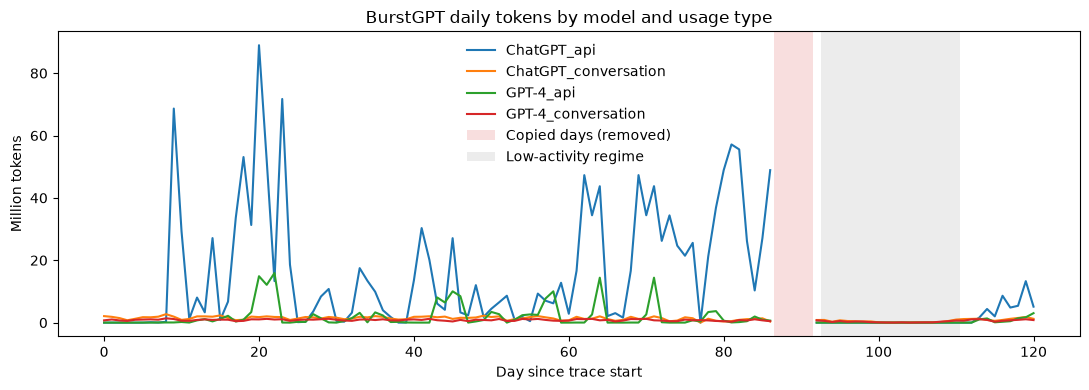

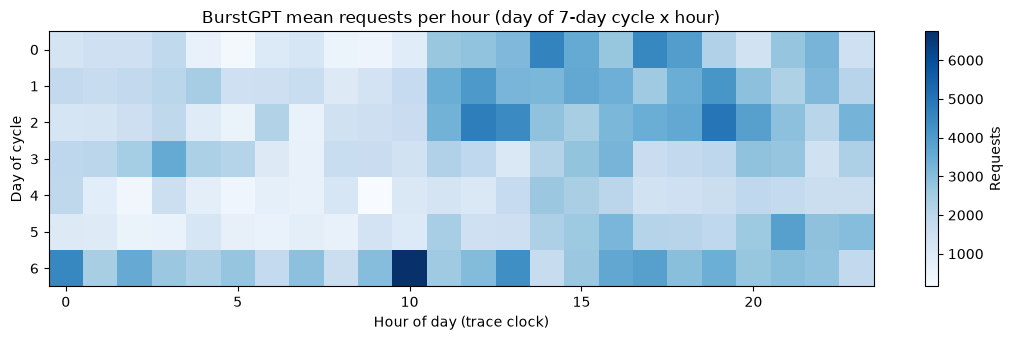

In [19]:
try:
    run()
except FileNotFoundError as e:
    print("SKIPPED:", e)

## 4. WildChat — usage growth & workforce enablement (core dataset)

**Preprocessing decisions**
- Streams one Parquet row group at a time; stores **no conversation text**.
- Fields are read wherever they exist (top-level or per-turn); the quality report lists the source used. If any shard lacks token counts, `user_tokens_charest` (characters ÷ 4) is the consistent fallback.
- A user = hashed IP (imperfect: shared or changing IPs). Partial first/last weeks and months are flagged.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

CHARS_PER_TOKEN = 4.0  # fallback estimate only when token counts are absent

In [21]:
def _turn_field(conv: pa.ChunkedArray | pa.Array, name: str):
    """Return (flattened per-turn values, parent row index) for a struct field, or None."""
    if isinstance(conv, pa.ChunkedArray):
        conv = conv.combine_chunks()
    struct_type = conv.type.value_type
    if name not in [f.name for f in struct_type]:
        return None
    flat = pc.list_flatten(conv)
    parents = pc.list_parent_indices(conv).to_numpy()
    return pc.struct_field(flat, name), parents

In [22]:
def process_table(t: pa.Table, used: dict) -> pd.DataFrame:
    n = t.num_rows
    names = t.column_names
    out = pd.DataFrame({
        "timestamp": pd.to_datetime(t.column("timestamp").to_pandas(), utc=True),
        "model": t.column("model").to_pandas().astype(str),
    })
    conv = t.column("conversation")

    # --- user identifier (hashed IP): top-level or first turn
    if "hashed_ip" in names:
        out["user_hash"] = t.column("hashed_ip").to_pandas().astype(str); used.setdefault("user_hash", set()).add("top-level hashed_ip")
    else:
        r = _turn_field(conv, "hashed_ip")
        if r is not None:
            vals, parents = r
            s = pd.Series(vals.to_pandas().values, index=parents)
            out["user_hash"] = s.groupby(level=0).first().reindex(range(n)).astype(str).values
            used.setdefault("user_hash", set()).add("per-turn hashed_ip (first turn)")
        else:
            out["user_hash"] = np.nan; used.setdefault("user_hash", set()).add("NOT AVAILABLE")

    for col in ("country", "language"):
        if col in names:
            out[col] = t.column(col).to_pandas()

    # --- per-turn role, token counts and lengths
    role = _turn_field(conv, "role")
    content = _turn_field(conv, "content")
    tokens = _turn_field(conv, "token_counter")
    lens = conv.combine_chunks() if isinstance(conv, pa.ChunkedArray) else conv
    out["n_turns_raw"] = pc.list_value_length(lens).to_numpy(zero_copy_only=False)

    if role is not None and content is not None:
        roles = role[0].to_pandas().values
        parents = role[1]
        chars = pc.utf8_length(pc.fill_null(content[0], "")).to_numpy(zero_copy_only=False)
        df = pd.DataFrame({"row": parents, "role": roles, "chars": chars})
        if tokens is not None:
            df["tok"] = tokens[0].to_pandas().values
            used.setdefault("tokens", set()).add("per-turn token_counter")
        else:
            df["tok"] = df["chars"] / CHARS_PER_TOKEN
            used.setdefault("tokens", set()).add(f"ESTIMATED from characters / {CHARS_PER_TOKEN}")
        df["tok_est"] = df["chars"] / CHARS_PER_TOKEN
        is_user = df["role"] == "user"
        g_user = df[is_user].groupby("row")
        g_asst = df[~is_user].groupby("row")
        out["user_turns"] = g_user.size().reindex(range(n), fill_value=0).values
        out["user_tokens"] = g_user["tok"].sum().reindex(range(n), fill_value=0).values
        out["assistant_tokens"] = g_asst["tok"].sum().reindex(range(n), fill_value=0).values
        out["user_tokens_charest"] = g_user["tok_est"].sum().reindex(range(n), fill_value=0).values
        out["first_prompt_tokens"] = g_user["tok_est"].first().reindex(range(n)).values
    else:
        used.setdefault("tokens", set()).add("NOT AVAILABLE (no role/content fields)")
        for c in ("user_turns", "user_tokens", "assistant_tokens", "user_tokens_charest", "first_prompt_tokens"):
            out[c] = np.nan
    return out

In [23]:
def load_conversations() -> pd.DataFrame:
    files = sorted((RAW / "wildchat").rglob("*.parquet"))
    if not files:
        raise FileNotFoundError("No WildChat Parquet shards in data/raw/wildchat - run download.py")
    used: dict = {}
    parts = []
    for i, f in enumerate(files, 1):
        pf = pq.ParquetFile(f)
        want = [c for c in ("timestamp", "model", "conversation", "hashed_ip", "country", "language")
                if c in pf.schema_arrow.names]
        for rg in range(pf.num_row_groups):
            parts.append(process_table(pf.read_row_group(rg, columns=want), used))
        print(f"  shard {i}/{len(files)}: {f.name}")
    d = pd.concat(parts, ignore_index=True)
    sources = {k: sorted(v) for k, v in used.items()}
    log_quality("WildChat", shards=len(files), field_sources=sources)
    if len(sources.get("tokens", [])) > 1:
        log_quality("WildChat", WARNING="token counts come from different methods across shards; "
                    "use user_tokens_charest for a consistent series")
    return d

In [24]:
def clean(d: pd.DataFrame) -> pd.DataFrame:
    n0 = len(d)
    d = d.dropna(subset=["timestamp"])
    d = d[d["user_turns"].fillna(1) > 0]  # drop conversations with no user turn
    d["model_family"] = np.where(d["model"].str.contains("gpt-4|o1|o3|o4", case=False, regex=True),
                                 "gpt4_family", "gpt35_family")
    d["total_tokens"] = d["user_tokens"].fillna(0) + d["assistant_tokens"].fillna(0)
    d["date"] = d["timestamp"].dt.tz_convert("UTC").dt.floor("D").dt.tz_localize(None)
    d["week"] = d["date"].dt.to_period("W-SUN").dt.start_time
    d["month"] = d["date"].dt.to_period("M").dt.to_timestamp()
    has_user = d["user_hash"].notna() & (d["user_hash"] != "nan")
    first_seen = d[has_user].groupby("user_hash")["date"].min().rename("user_first_date")
    d = d.merge(first_seen, on="user_hash", how="left")
    d["is_first_conversation_day"] = d["date"] == d["user_first_date"]
    d = d.sort_values("timestamp")
    log_quality("WildChat",
                rows_raw=n0, rows_clean=len(d),
                period=f"{d['date'].min().date()} to {d['date'].max().date()}",
                models=d["model"].value_counts().head(10).to_dict(),
                users_with_hash=int(first_seen.size),
                user_id_caveat="hashed IP is an imperfect user ID (shared/changing IPs)",
                token_check="compare user_tokens vs user_tokens_charest in wildchat_conversations")
    return d

In [25]:
def daily(d: pd.DataFrame) -> pd.DataFrame:
    g = d.groupby(["date", "model_family"])
    out = g.agg(conversations=("timestamp", "size"), total_tokens=("total_tokens", "sum"),
                user_tokens=("user_tokens", "sum"), assistant_tokens=("assistant_tokens", "sum"),
                active_users=("user_hash", "nunique")).reset_index()
    new = (d[d["is_first_conversation_day"]].groupby(["date", "model_family"])["user_hash"]
           .nunique().rename("new_users"))
    out = out.merge(new, on=["date", "model_family"], how="left").fillna({"new_users": 0})
    full = pd.MultiIndex.from_product(
        [pd.date_range(d["date"].min(), d["date"].max(), freq="D"), sorted(d["model_family"].unique())],
        names=["date", "model_family"])
    out = out.set_index(["date", "model_family"]).reindex(full).reset_index()
    out["missing_day"] = out["conversations"].isna()
    return out.fillna(0)

In [26]:
def weekly(d: pd.DataFrame) -> pd.DataFrame:
    w = d.groupby("week").agg(conversations=("timestamp", "size"), total_tokens=("total_tokens", "sum"),
                              active_users=("user_hash", "nunique"),
                              avg_user_turns=("user_turns", "mean"),
                              median_first_prompt_tokens=("first_prompt_tokens", "median"))
    new_users = d[d["is_first_conversation_day"]].groupby("week")["user_hash"].nunique()
    w["new_users"] = new_users.reindex(w.index, fill_value=0)
    # returning share: active users this week who were first seen in an EARLIER week
    first_week = d.groupby("user_hash")["week"].min()
    dd = d[["week", "user_hash"]].drop_duplicates()
    dd["returning"] = dd["week"] > dd["user_hash"].map(first_week)
    w["returning_users"] = dd.groupby("week")["returning"].sum().reindex(w.index, fill_value=0)
    w["returning_share"] = w["returning_users"] / w["active_users"].replace(0, np.nan)
    w["tokens_per_active_user"] = w["total_tokens"] / w["active_users"].replace(0, np.nan)
    w = w.reset_index()
    # Partial first/last weeks distort trends - flag them.
    days = d.groupby("week")["date"].nunique()
    w["partial_week"] = w["week"].map(days).fillna(0) < 7
    return w

In [27]:
def monthly(d: pd.DataFrame) -> pd.DataFrame:
    m = d.groupby(["month", "model_family"]).agg(conversations=("timestamp", "size"),
                                                 total_tokens=("total_tokens", "sum"),
                                                 active_users=("user_hash", "nunique")).reset_index()
    days = d.groupby("month")["date"].nunique()
    m["days_observed"] = m["month"].map(days)
    m["days_in_month"] = m["month"].dt.days_in_month
    m["partial_month"] = m["days_observed"] < m["days_in_month"]
    return m

In [28]:
def plots(w: pd.DataFrame):
    import matplotlib
    import matplotlib.pyplot as plt
    w = w[~w["partial_week"]]
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    axes[0].plot(w["week"], w["total_tokens"] / 1e6)
    axes[0].set(title="WildChat weekly tokens", ylabel="Million tokens")
    axes[1].plot(w["week"], w["new_users"], label="New users")
    axes[1].plot(w["week"], w["returning_users"], label="Returning users")
    axes[1].set(title="Weekly new vs returning users (enablement proxy)", ylabel="Users")
    axes[1].legend(frameon=False)
    fig.tight_layout(); fig.savefig(FIGURES / "wildchat_weekly.png", dpi=150); plt.show()

In [29]:
def run():
    print("WildChat")
    d = clean(load_conversations())
    keep = ["timestamp", "date", "model", "model_family", "user_hash", "country", "language",
            "n_turns_raw", "user_turns", "user_tokens", "assistant_tokens", "total_tokens",
            "user_tokens_charest", "first_prompt_tokens", "is_first_conversation_day"]
    save(d[[c for c in keep if c in d.columns]], "wildchat_conversations")
    dl = daily(d); save(dl, "wildchat_daily")
    w = weekly(d); save(w, "wildchat_weekly")
    save(monthly(d), "wildchat_monthly")
    tot = dl.groupby("date")["total_tokens"].sum()
    log_quality("WildChat", missing_days=int(dl.groupby("date")["missing_day"].all().sum()),
                adf_daily_total_tokens=adf_summary(tot),
                adf_weekly_new_users=adf_summary(w.loc[~w["partial_week"], "new_users"]))
    plots(w)

WildChat
  shard 1/5: train-00000-of-00086.parquet
  shard 2/5: train-00001-of-00086.parquet
  shard 3/5: train-00002-of-00086.parquet
  shard 4/5: train-00003-of-00086.parquet
  shard 5/5: train-00004-of-00086.parquet
  saved wildchat_conversations: 186,040 rows x 15 cols
  saved wildchat_daily: 132 rows x 9 cols
  saved wildchat_weekly: 11 rows x 11 cols
  saved wildchat_monthly: 6 rows x 8 cols


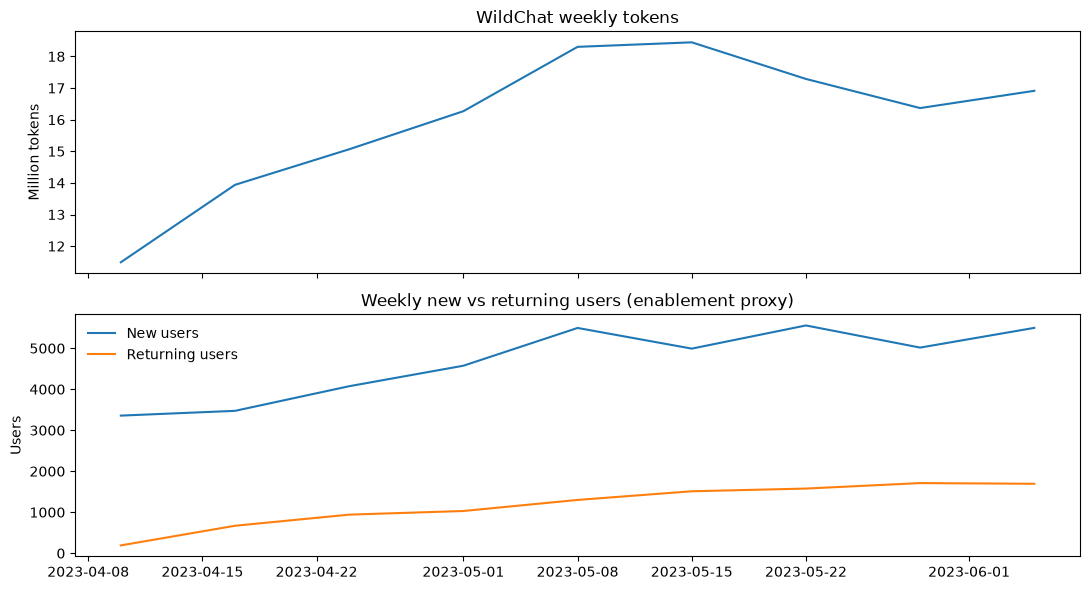

In [30]:
try:
    run()
except FileNotFoundError as e:
    print("SKIPPED:", e)

## 5. FRED / BLS — wages, cloud prices, AI time savings

**Preprocessing decisions**
- FRED's `.` gap markers → missing → dropped (counts reported).
- ECI is modelled **quarterly**; the monthly version is linear interpolation for the cost engine only, never for fitting.
- The GenAI tracker has ~7 quarterly points → trend models / pooled regression later, not ARIMA.

In [31]:
# FRED_SERIES is defined in the download section above
print(len(FRED_SERIES), 'series')

14 series


In [32]:
from pathlib import Path
import pandas as pd

def read_series(sid: str) -> pd.DataFrame | None:
    f = RAW / "fred" / f"{sid}.csv"
    if not f.exists():
        return None
    d = pd.read_csv(f)
    date_col = d.columns[0]          # 'observation_date' (or 'DATE' in older exports)
    d = d.rename(columns={date_col: "date", d.columns[1]: "value"})
    d["date"] = pd.to_datetime(d["date"])
    d["value"] = pd.to_numeric(d["value"], errors="coerce")  # FRED marks gaps with '.'
    d["series_id"] = sid
    d["description"] = FRED_SERIES.get(sid, "")
    return d

In [33]:
def run():
    print("FRED / BLS")
    frames, missing = [], []
    for sid in FRED_SERIES:
        d = read_series(sid)
        (frames if d is not None else missing).append(d if d is not None else sid)
    if not frames:
        raise FileNotFoundError("No FRED CSVs in data/raw/fred - run download.py --only fred")
    long = pd.concat(frames, ignore_index=True)
    gaps = long.groupby("series_id")["value"].apply(lambda s: int(s.isna().sum()))
    long = long.dropna(subset=["value"])
    save(long, "fred_long")

    def wide(ids):
        sub = long[long["series_id"].isin(ids)]
        return sub.pivot_table(index="date", columns="series_id", values="value").reset_index()

    eci_ids = [s for s in ("CIS202540A000000I", "CIU202540A000000I") if s in set(long.series_id)]
    if eci_ids:
        eci = wide(eci_ids).rename(columns={"CIS202540A000000I": "eci_wages_sa",
                                           "CIU202540A000000I": "eci_wages_nsa"})
        eci["quarter"] = eci["date"].dt.quarter
        save(eci, "eci_quarterly")
        # Monthly view: place each quarterly index at the quarter's middle month, interpolate.
        m = eci.set_index(eci["date"] + pd.DateOffset(months=1))[["eci_wages_sa"]]
        m = m.resample("MS").mean().interpolate("linear").reset_index().rename(columns={"index": "date"})
        m["note"] = "interpolated from quarterly; use only in the cost engine, not for model fitting"
        save(m, "eci_monthly")
        if "eci_wages_sa" in eci:
            log_quality("BLS ECI", period=f"{eci.date.min().date()} to {eci.date.max().date()}",
                        n_quarters=len(eci), adf_sa_level=adf_summary(eci["eci_wages_sa"]),
                        adf_sa_diff=adf_summary(eci["eci_wages_sa"].diff()))

    ppi_ids = [s for s in ("PCU518210518210", "PCU5182105182105") if s in set(long.series_id)]
    if ppi_ids:
        ppi = wide(ppi_ids).rename(columns={"PCU518210518210": "ppi_hosting",
                                           "PCU5182105182105": "ppi_hosting_infra"})
        save(ppi, "ppi_hosting_monthly")
        log_quality("FRED PPI hosting", period=f"{ppi.date.min().date()} to {ppi.date.max().date()}",
                    n_months=len(ppi), adf_level=adf_summary(ppi["ppi_hosting"]),
                    adf_diff=adf_summary(ppi["ppi_hosting"].diff()))

    nat = [s for s in ("RPSGENAITSALL", "RPSGENAIASSISTWRKHRSALL") if s in set(long.series_id)]
    if nat:
        tr = wide(nat).rename(columns={"RPSGENAITSALL": "time_saved_pct_hours",
                                       "RPSGENAIASSISTWRKHRSALL": "hours_assisted_pct"})
        save(tr, "genai_tracker")
        log_quality("FRED GenAI Adoption Tracker", period=f"{tr.date.min().date()} to {tr.date.max().date()}",
                    n_quarters=len(tr),
                    caveat="too few points for ARIMA; use Holt trend / regression; self-reported")

    panel_ids = [s for s in FRED_SERIES if s.startswith("RPSGENAITS") and s != "RPSGENAITSALL"]
    panel = long[long["series_id"].isin(panel_ids)][["date", "series_id", "description", "value"]]
    if len(panel):
        panel = panel.rename(columns={"value": "time_saved_pct_hours"})
        panel["group_type"] = panel["series_id"].str.contains("OCC").map({True: "occupation", False: "industry"})
        save(panel, "genai_timesaved_panel")
        log_quality("FRED GenAI Adoption Tracker",
                    panel_series=int(panel.series_id.nunique()), panel_rows=len(panel),
                    panel_points_per_series=panel.groupby("series_id").size().to_dict())

    log_quality("FRED (all)", series_loaded=len(frames), series_missing=missing,
                missing_values_dropped=gaps[gaps > 0].to_dict())

In [34]:
try:
    run()
except FileNotFoundError as e:
    print("SKIPPED:", e)

FRED / BLS
SKIPPED: No FRED CSVs in data/raw/fred - run download.py --only fred


## 6. Epoch AI — price per token

**Preprocessing decisions**
- Column names are detected automatically (release date, input and output price per 1M tokens).
- Blended price = 0.83 × input + 0.17 × output; the 0.83 is the **measured** input-token share in BurstGPT.
- Irregular model releases → monthly *cheapest available price* (running minimum) → log-linear trend later.

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd

INPUT_WEIGHT = 0.83  # share of input tokens measured in BurstGPT_1

In [36]:
def pick(cols, *must, avoid=()):
    for c in cols:
        lc = c.lower()
        if all(m in lc for m in must) and not any(a in lc for a in avoid):
            return c
    return None

In [37]:
def run(date_col=None, input_col=None, output_col=None, name_col=None):
    print("Epoch AI prices")
    files = sorted((RAW / "epoch").glob("*.csv"))
    if not files:
        log_quality("Epoch AI", status="SKIPPED - put the CSV export in data/raw/epoch/ (see README)")
        raise FileNotFoundError("no CSV in data/raw/epoch (manual download, see README)")
    d = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    cols = list(d.columns)
    date_col = date_col or pick(cols, "release") or pick(cols, "date")
    input_col = input_col or pick(cols, "input", "price") or pick(cols, "input", "$")
    output_col = output_col or pick(cols, "output", "price") or pick(cols, "output", "$")
    name_col = name_col or pick(cols, "model") or pick(cols, "name") or cols[0]
    chosen = dict(date=date_col, input=input_col, output=output_col, name=name_col)
    print(f"  columns used: {chosen}")
    if not (date_col and input_col and output_col):
        raise ValueError(f"Could not detect columns, pass them explicitly. Available: {cols}")

    m = pd.DataFrame({
        "model": d[name_col].astype(str),
        "date": pd.to_datetime(d[date_col], errors="coerce"),
        "input_usd_per_mtok": pd.to_numeric(d[input_col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"),
        "output_usd_per_mtok": pd.to_numeric(d[output_col].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"),
    })
    n0 = len(m)
    m = m.dropna().query("input_usd_per_mtok > 0 and output_usd_per_mtok > 0").drop_duplicates()
    m["blended_usd_per_mtok"] = INPUT_WEIGHT * m["input_usd_per_mtok"] + (1 - INPUT_WEIGHT) * m["output_usd_per_mtok"]
    m["log_blended"] = np.log(m["blended_usd_per_mtok"])
    save(m.sort_values("date"), "epoch_prices_models")

    m["month"] = m["date"].dt.to_period("M").dt.to_timestamp()
    monthly = m.groupby("month").agg(models_released=("model", "size"),
                                     min_blended=("blended_usd_per_mtok", "min"),
                                     median_blended=("blended_usd_per_mtok", "median")).reset_index()
    # Running cheapest price available so far (a price frontier, irregular -> monthly).
    full = pd.DataFrame({"month": pd.date_range(monthly.month.min(), monthly.month.max(), freq="MS")})
    monthly = full.merge(monthly, on="month", how="left")
    monthly["models_released"] = monthly["models_released"].fillna(0).astype(int)
    monthly["cheapest_available"] = monthly["min_blended"].cummin().ffill()
    save(monthly, "epoch_prices_monthly")
    log_quality("Epoch AI", columns_used=chosen, rows_raw=n0, models_with_price=len(m),
                period=f"{m.date.min().date()} to {m.date.max().date()}",
                months_without_new_model=int((monthly.models_released == 0).sum()),
                caveat="irregular release dates; fit a log-linear trend, not SARIMA")

In [38]:
try:
    run()
except FileNotFoundError as e:
    print("SKIPPED:", e)

Epoch AI prices
SKIPPED: no CSV in data/raw/epoch (manual download, see README)


## 7. METR RCT — downside case for time saved

Not a time series. It supplies evidence that AI can **slow** some experienced workers down, which sets the downside of the business-outcome range. The citable effect is the paper's regression (+18.8% time with AI); the ratio here is a simple check.

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd

def run():
    print("METR RCT")
    f = RAW / "metr" / "data_complete.csv"
    if not f.exists():
        raise FileNotFoundError("data/raw/metr/data_complete.csv missing - run download.py --only metr")
    d = pd.read_csv(f)
    n0 = len(d)
    d = d.dropna(subset=["ai_treatment", "initial_implementation_time"])
    d = d[d["initial_implementation_time"] > 0]
    d["ai_treatment"] = d["ai_treatment"].astype(int)
    d["log_time"] = np.log(d["initial_implementation_time"])
    d["log_pred_no_ai"] = np.log(d["predicted_time_no_ai"])
    d["forecast_speedup_expected"] = d["predicted_time_no_ai"] / d["predicted_time_ai_allowed"] - 1
    save(d, "metr_tasks")

    s = d.groupby("ai_treatment").agg(tasks=("issue_id", "size"),
                                      mean_minutes=("initial_implementation_time", "mean"),
                                      median_minutes=("initial_implementation_time", "median")).reset_index()
    s["arm"] = s["ai_treatment"].map({0: "AI not allowed", 1: "AI allowed"})
    save(s, "metr_effect_summary")
    ratio = s.loc[s.ai_treatment == 1, "mean_minutes"].item() / s.loc[s.ai_treatment == 0, "mean_minutes"].item() - 1
    log_quality("METR RCT", rows_raw=n0, rows_clean=len(d), developers=int(d.dev_id.nunique()),
                naive_time_change_with_ai=f"{ratio:+.1%} (ratio of mean times; not the paper's regression)",
                paper_estimate="+18.8% time with AI (95% CI ~+1% to +39%), per repo README",
                use="downside bound for hours-saved scenario")

In [40]:
try:
    run()
except FileNotFoundError as e:
    print("SKIPPED:", e)

METR RCT
  saved metr_tasks: 246 rows x 12 cols
  saved metr_effect_summary: 2 rows x 5 cols


## 8. Readiness checks for the review (Module 1 & 3)
These are not models yet — they show each core series is understood and ready to model:
decomposition (trend / seasonality / noise), stationarity, and ACF/PACF for order selection.

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.seasonal import STL, MSTL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def exists(name):
    return (PROCESSED / f"{name}.parquet").exists()

def show_acf_pacf(s, lags, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    plot_acf(s, lags=lags, ax=ax[0]); plot_pacf(s, lags=lags, ax=ax[1], method="ywm")
    ax[0].set_title(f"ACF — {title}"); ax[1].set_title(f"PACF — {title}")
    fig.tight_layout(); plt.show()

### 8.1 BurstGPT — hourly requests in the modelling window: daily (24 h) and weekly (168 h) seasonality

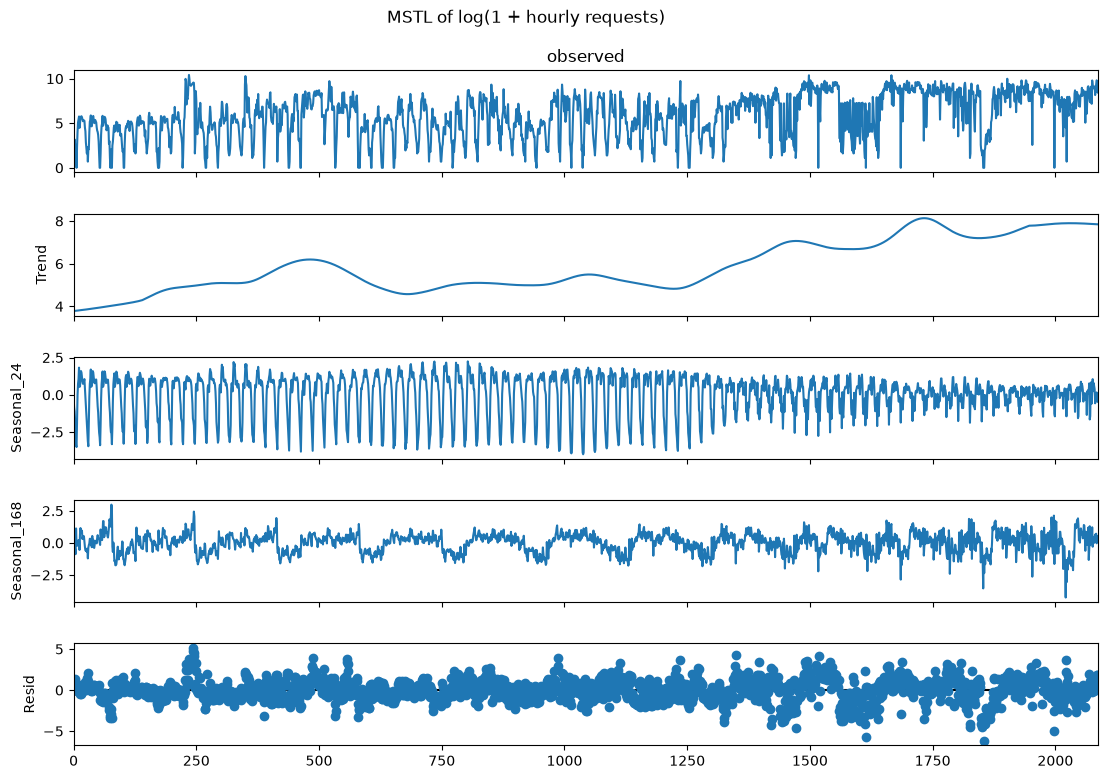

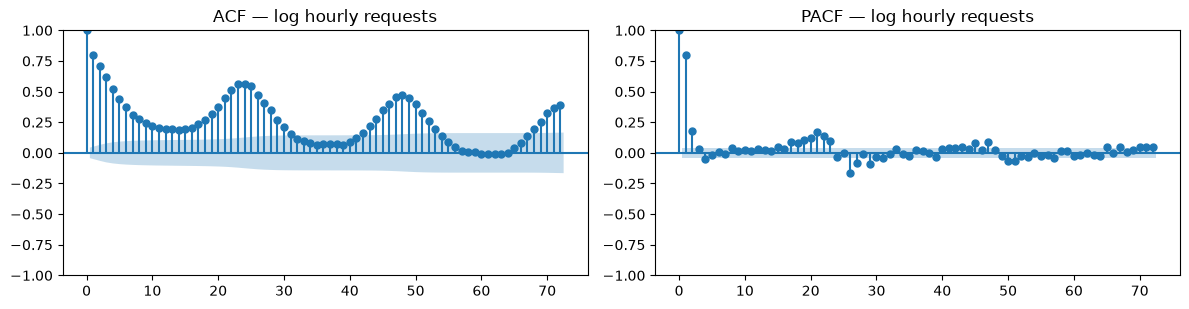

Raw: {'n': 2088, 'adf_p': np.float64(0.0021), 'kpss_p': np.float64(0.01), 'verdict': 'non-stationary (difference before ARMA)'}
Seasonally differenced (lag 24): {'n': 2064, 'adf_p': np.float64(0.0), 'kpss_p': np.float64(0.1), 'verdict': 'stationary'}


In [42]:
if exists("burstgpt_hourly_total"):
    h = pd.read_parquet(PROCESSED / "burstgpt_hourly_total.parquet")
    h = h[h["in_model_window"] == True]          # clean modelling window only
    s = h.set_index("hour_index")["requests"].astype(float)
    res = MSTL(np.log1p(s), periods=(24, 168)).fit()
    res.plot(); plt.gcf().set_size_inches(12, 8); plt.suptitle("MSTL of log(1 + hourly requests)", y=1.0); plt.show()
    show_acf_pacf(np.log1p(s), 72, "log hourly requests")
    print("Raw:", adf_summary(s)); print("Seasonally differenced (lag 24):", adf_summary(np.log1p(s).diff(24)))

### 8.2 BurstGPT — daily tokens by segment: which series are forecastable?

,mean_million_tokens,coef_of_variation,share_of_tokens
ChatGPT_api_total_tokens,17.460,1.142,0.799
ChatGPT_conversation_total_tokens,1.438,0.370,0.066
GPT-4_api_total_tokens,2.111,1.794,0.097
GPT-4_conversation_total_tokens,0.841,0.295,0.038


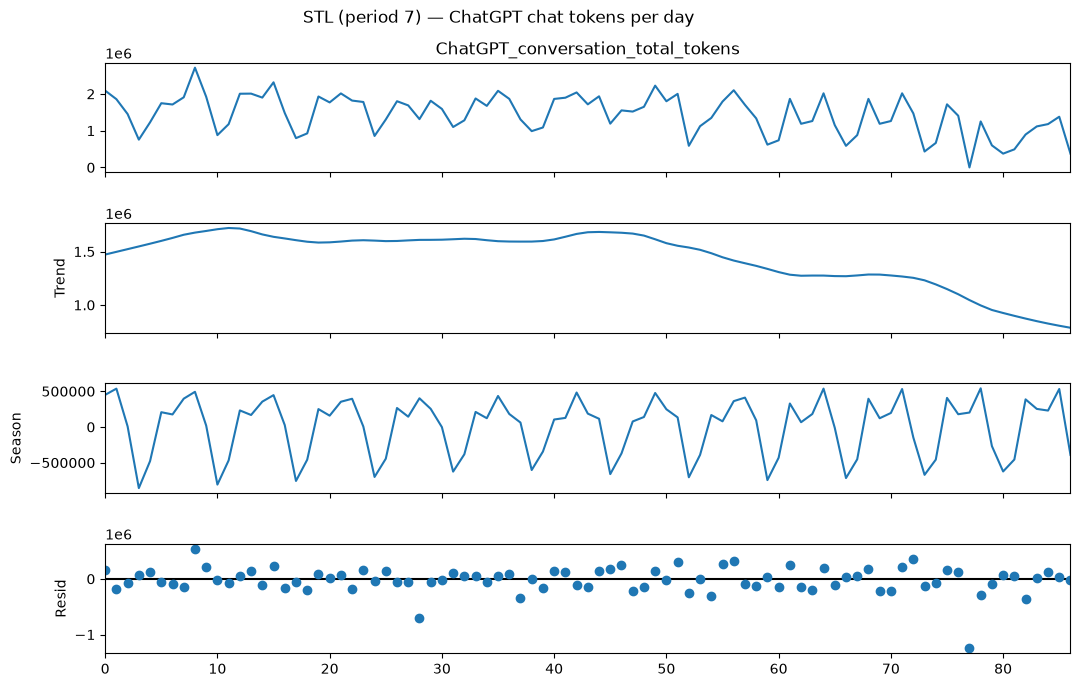

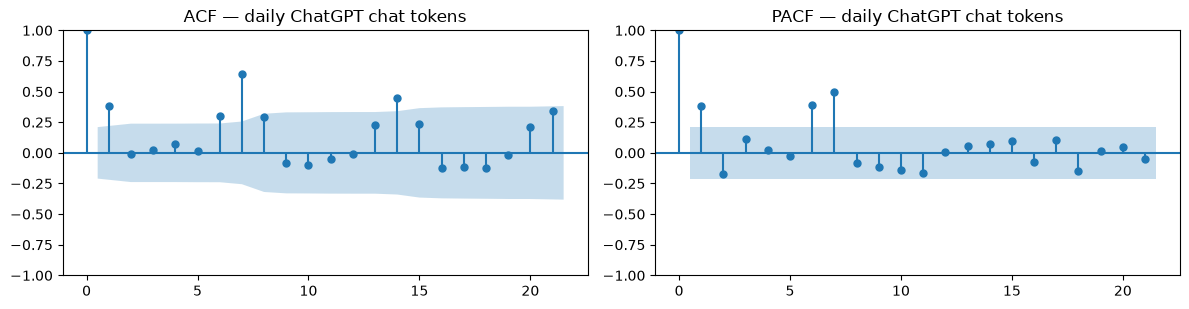

ChatGPT_api_total_tokens               {'n': 87, 'adf_p': np.float64(0.0), 'kpss_p': np.float64(0.1), 'verdict': 'stationary'}
ChatGPT_conversation_total_tokens      {'n': 87, 'adf_p': np.float64(0.9726), 'kpss_p': np.float64(0.01), 'verdict': 'non-stationary (difference before ARMA)'}
GPT-4_api_total_tokens                 {'n': 87, 'adf_p': np.float64(0.0), 'kpss_p': np.float64(0.1), 'verdict': 'stationary'}
GPT-4_conversation_total_tokens        {'n': 87, 'adf_p': np.float64(0.6604), 'kpss_p': np.float64(0.0712), 'verdict': 'non-stationary (difference before ARMA)'}


In [43]:
if exists("burstgpt_daily_wide"):
    w = pd.read_parquet(PROCESSED / "burstgpt_daily_wide.parquet")
    w = w[w["in_model_window"]]                 # clean modelling window only
    seg_cols = [c for c in w.columns if c.endswith("_total_tokens") and c != "total_tokens"]
    stats = pd.DataFrame({
        "mean_million_tokens": w[seg_cols].mean() / 1e6,
        "coef_of_variation": w[seg_cols].std() / w[seg_cols].mean(),
        "share_of_tokens": w[seg_cols].sum() / w[seg_cols].sum().sum(),
    }).round(3)
    display(stats)
    conv = w.set_index("day_index")["ChatGPT_conversation_total_tokens"].astype(float)
    STL(conv, period=7, robust=True).fit().plot(); plt.gcf().set_size_inches(12, 7)
    plt.suptitle("STL (period 7) — ChatGPT chat tokens per day", y=1.0); plt.show()
    show_acf_pacf(conv, 21, "daily ChatGPT chat tokens")
    for c in seg_cols:
        print(f"{c:38s}", adf_summary(w[c]))

### 8.3 WildChat — weekly usage and enablement proxies

,conversations,total_tokens,active_users,new_users,returning_share,avg_user_turns,median_first_prompt_tokens
count,9.00,9.00,9.00,9.00,9.00,9.00,9.00
mean,19908.67,16008263.33,5850.89,4670.33,0.19,2.65,20.40
std,4585.22,2220425.64,1346.40,858.31,0.06,0.26,4.01
min,11929.00,11489907.00,3548.00,3357.00,0.05,2.17,16.75
25%,17168.00,15063921.00,5015.00,4074.00,0.18,2.49,17.75
50%,21412.00,16366297.00,6502.00,4991.00,0.19,2.67,18.88
75%,22562.00,17287330.00,6795.00,5495.00,0.23,2.85,22.25
max,27234.00,18445420.00,7191.00,5556.00,0.25,2.99,29.50


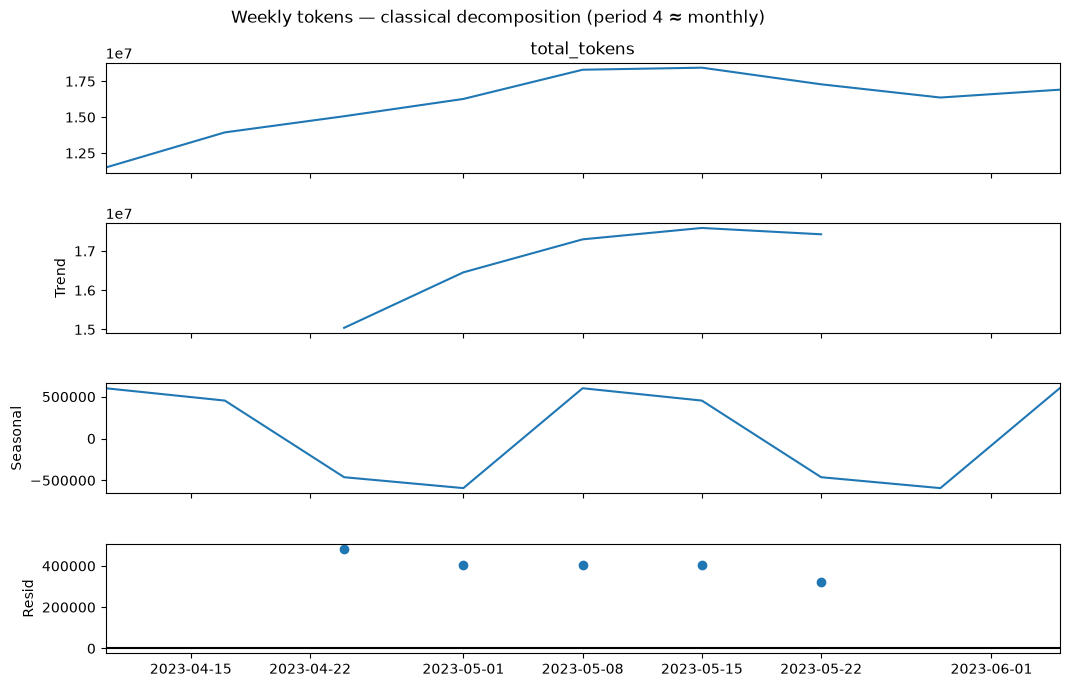

Weekly tokens: {'n': 9, 'note': 'too short for tests'}
Weekly new users: {'n': 9, 'note': 'too short for tests'}


In [44]:
if exists("wildchat_weekly"):
    ww = pd.read_parquet(PROCESSED / "wildchat_weekly.parquet")
    ww = ww[~ww["partial_week"]].set_index("week")
    display(ww[["conversations", "total_tokens", "active_users", "new_users", "returning_share",
                "avg_user_turns", "median_first_prompt_tokens"]].describe().round(2))
    if len(ww) >= 2 * 4 + 1:
        seasonal_decompose(ww["total_tokens"], model="additive", period=4).plot()
        plt.gcf().set_size_inches(12, 7); plt.suptitle("Weekly tokens — classical decomposition (period 4 ≈ monthly)", y=1.0); plt.show()
    print("Weekly tokens:", adf_summary(ww["total_tokens"]))
    print("Weekly new users:", adf_summary(ww["new_users"]))

### 8.4 ECI wages — quarterly seasonality (NSA) and trend

In [45]:
if exists("eci_quarterly"):
    e = pd.read_parquet(PROCESSED / "eci_quarterly.parquet").set_index("date")
    col = "eci_wages_nsa" if "eci_wages_nsa" in e else "eci_wages_sa"
    seasonal_decompose(e[col].dropna(), model="multiplicative", period=4).plot()
    plt.gcf().set_size_inches(12, 7); plt.suptitle(f"{col} — multiplicative decomposition (s=4)", y=1.0); plt.show()
    logd = np.log(e[col].dropna()).diff().dropna()
    show_acf_pacf(logd, 16, "ECI quarterly log-growth")
    print("Level:", adf_summary(e[col])); print("Log-difference:", adf_summary(logd))

### 8.5 Prices and outcomes at a glance

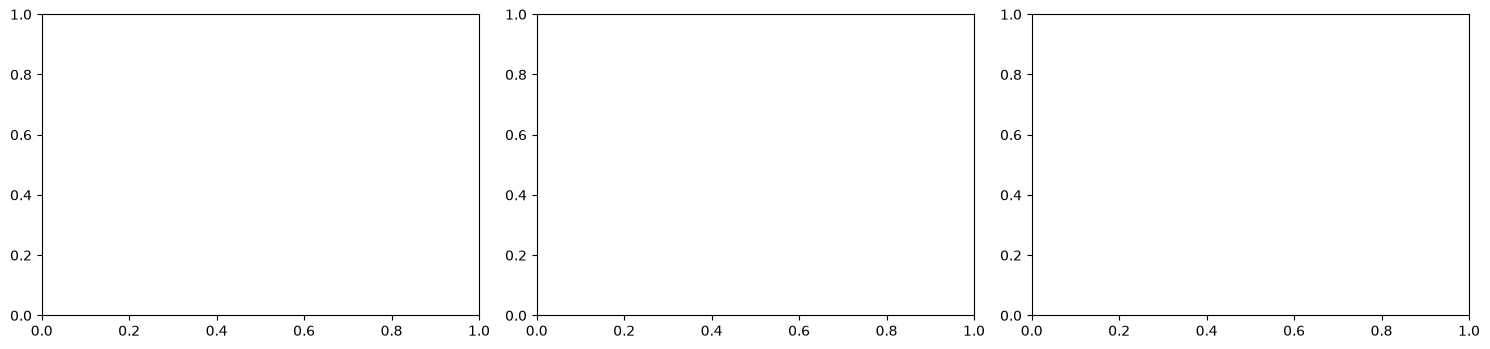

,ai_treatment,tasks,mean_minutes,median_minutes,arm
0,0,110,90.900000,65.0,AI not allowed
1,1,136,119.540441,76.0,AI allowed


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
if exists("ppi_hosting_monthly"):
    p = pd.read_parquet(PROCESSED / "ppi_hosting_monthly.parquet")
    axes[0].plot(p["date"], p["ppi_hosting"]); axes[0].set_title("PPI hosting (Dec 2000 = 100)")
if exists("epoch_prices_monthly"):
    ep = pd.read_parquet(PROCESSED / "epoch_prices_monthly.parquet")
    axes[1].semilogy(ep["month"], ep["cheapest_available"]); axes[1].set_title("Cheapest blended $/1M tokens (log)")
if exists("genai_tracker"):
    g = pd.read_parquet(PROCESSED / "genai_tracker.parquet")
    for c in [c for c in g.columns if c != "date"]:
        axes[2].plot(g["date"], g[c], marker="o", label=c)
    axes[2].set_title("GenAI tracker (% of work hours)"); axes[2].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
if exists("metr_effect_summary"):
    display(pd.read_parquet(PROCESSED / "metr_effect_summary.parquet"))

## 9. Summary of processed outputs and quality report

In [47]:
rows = []
for p in sorted(PROCESSED.glob("*.parquet")):
    d = pd.read_parquet(p)
    rows.append({"table": p.stem, "rows": len(d), "columns": d.shape[1], "MB": round(p.stat().st_size / 1e6, 2)})
display(pd.DataFrame(rows))

from IPython.display import Markdown
display(Markdown(write_quality_report().read_text()))

,table,rows,columns,MB
0,burstgpt_daily,484,9,0.02
1,burstgpt_daily_wide,121,18,0.02
2,burstgpt_hourly,11616,9,0.20
3,burstgpt_hourly_total,2904,12,0.07
4,burstgpt_requests_clean,4804926,10,32.77
5,metr_effect_summary,2,5,0.00
6,metr_tasks,246,12,0.01
7,wildchat_conversations,186040,15,8.79
8,wildchat_daily,132,9,0.01
9,wildchat_monthly,6,8,0.01


Quality report -> c:\Users\Isha Jain\Downloads\ai-workforce-intel\reports\data_quality.md


# Data quality report

Generated by `python src/run_all.py`. Re-run after adding new raw files.

## BurstGPT

- **files:** `["BurstGPT_1.csv", "BurstGPT_2.csv"]`
- **rows_raw:** 5288173
- **rows_clean:** 5288173
- **span_days:** 121.0
- **time_axis:** relative seconds from trace start (no calendar dates)
- **models:** `{"ChatGPT": 4970268, "GPT-4": 317905}`
- **log_types:** `{"api": 5052894, "conversation": 235279}`
- **failure_rate:** 1.88%
- **total_token_mismatches_fixed:** 0
- **exact_duplicate_rows_kept:** 204190
- **copied_days:** `{"87": "copy of day 81", "88": "copy of day 82", "89": "copy of day 83", "90": "copy of day 84", "91": "copy of day 85"}`
- **copied_rows_removed:** 483247
- **low_activity_days:** 93-110 (18 days, <10% of median requests)
- **anomaly_low_days:** `[77]`
- **model_window_days:** 0-86 (87 clean consecutive days)
- **weekly_pattern:** `{"likely_weekend_day_of_cycle": [4, 5], "weekend_to_weekday_volume_ratio": 0.72, "note": "if the ratio is not clearly < 1, treat weekday alignment as unknown"}`
- **adf_daily_total_tokens_window:** `{"n": 87, "adf_p": 0.0, "kpss_p": 0.1, "verdict": "stationary"}`
- **adf_hourly_requests_window:** `{"n": 2088, "adf_p": 0.0021, "kpss_p": 0.01, "verdict": "non-stationary (difference before ARMA)"}`
- **empty_hours_in_window:** 43

## WildChat

- **shards:** 5
- **field_sources:** `{"user_hash": ["top-level hashed_ip"], "tokens": ["per-turn token_counter"]}`
- **rows_raw:** 186040
- **rows_clean:** 186040
- **period:** 2023-04-09 to 2023-06-13
- **models:** `{"gpt-3.5-turbo-0301": 142792, "gpt-4-0314": 43248}`
- **users_with_hash:** 43922
- **user_id_caveat:** hashed IP is an imperfect user ID (shared/changing IPs)
- **token_check:** compare user_tokens vs user_tokens_charest in wildchat_conversations
- **missing_days:** 0
- **adf_daily_total_tokens:** `{"n": 66, "adf_p": 0.0731, "kpss_p": 0.01, "verdict": "non-stationary (difference before ARMA)"}`
- **adf_weekly_new_users:** `{"n": 9, "note": "too short for tests"}`

## Epoch AI

- **status:** SKIPPED - put the CSV export in data/raw/epoch/ (see README)

## METR RCT

- **rows_raw:** 246
- **rows_clean:** 246
- **developers:** 16
- **naive_time_change_with_ai:** +31.5% (ratio of mean times; not the paper's regression)
- **paper_estimate:** +18.8% time with AI (95% CI ~+1% to +39%), per repo README
- **use:** downside bound for hours-saved scenario
